In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [16]:
df = pd.read_csv("uber.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [17]:
# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Column names
print("\nColumns:")
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000



Missing Values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

Duplicate Records: 0

Columns:
Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')


In [18]:
# Remove unnecessary columns
df.drop(columns=['Unnamed: 0', 'key'], errors='ignore', inplace=True)

# Convert datetime column
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce', utc=True
)

# Remove missing values
df.dropna(inplace=True)

# Remove invalid fare amounts
df = df[df['fare_amount'] > 0]

# Validate geographical coordinates
df = df[
    df['pickup_longitude'].between(-180, 180) &
    df['dropoff_longitude'].between(-180, 180) &
    df['pickup_latitude'].between(-90, 90) &
    df['dropoff_latitude'].between(-90, 90)
]

# Remove zero coordinates
coordinate_cols = [
    'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude'
]

df = df[(df[coordinate_cols] != 0).all(axis=1)]

# Passenger count validation
df = df[df['passenger_count'].between(1, 6)]

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Extract time features
df['pickup_hour'] = df['pickup_datetime'].dt.hour
df['pickup_day'] = df['pickup_datetime'].dt.day
df['pickup_month'] = df['pickup_datetime'].dt.month
df['pickup_weekday'] = df['pickup_datetime'].dt.dayofweek

print("Preprocessing completed!")
print("Remaining records:", df.shape)


Preprocessing completed!
Remaining records: (195313, 11)


In [19]:
def haversine(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2)**2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return 6371 * c

df['distance_km'] = haversine(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

# Remove unrealistic distances
df = df[df['distance_km'].between(0.1, 100)]

df[['distance_km', 'fare_amount']].head()


,distance_km,fare_amount
0,1.683323,7.5
1,2.457590,7.7
2,5.036377,12.9
3,1.661683,5.3
4,4.475450,16.0


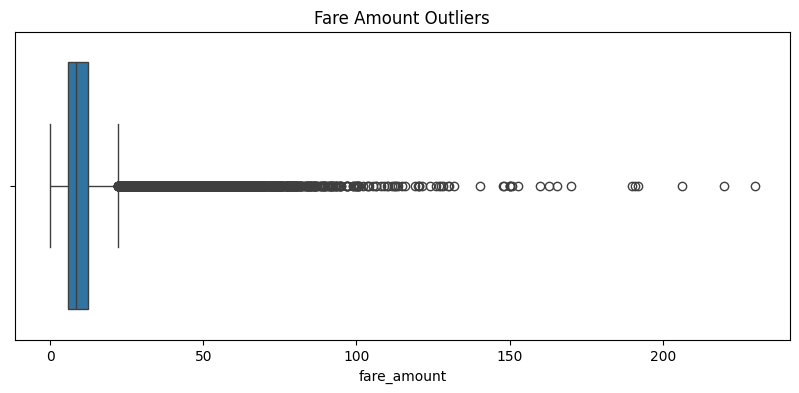

Number of outliers: 16309


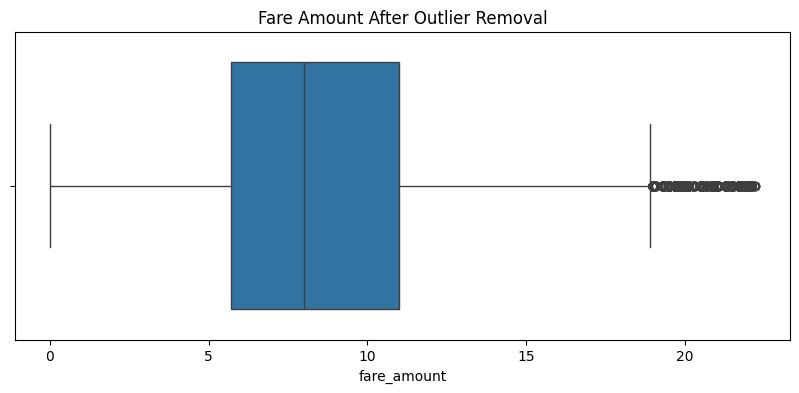

Outliers removed successfully!


In [20]:
# Boxplot before removing outliers
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount Outliers")
plt.show()

# IQR method
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Count outliers
outliers = df[
    (df['fare_amount'] < lower) |
    (df['fare_amount'] > upper)
]

print("Number of outliers:", len(outliers))

# Remove fare outliers
df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]

# Boxplot after removing outliers
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount After Outlier Removal")
plt.show()

print("Outliers removed successfully!")


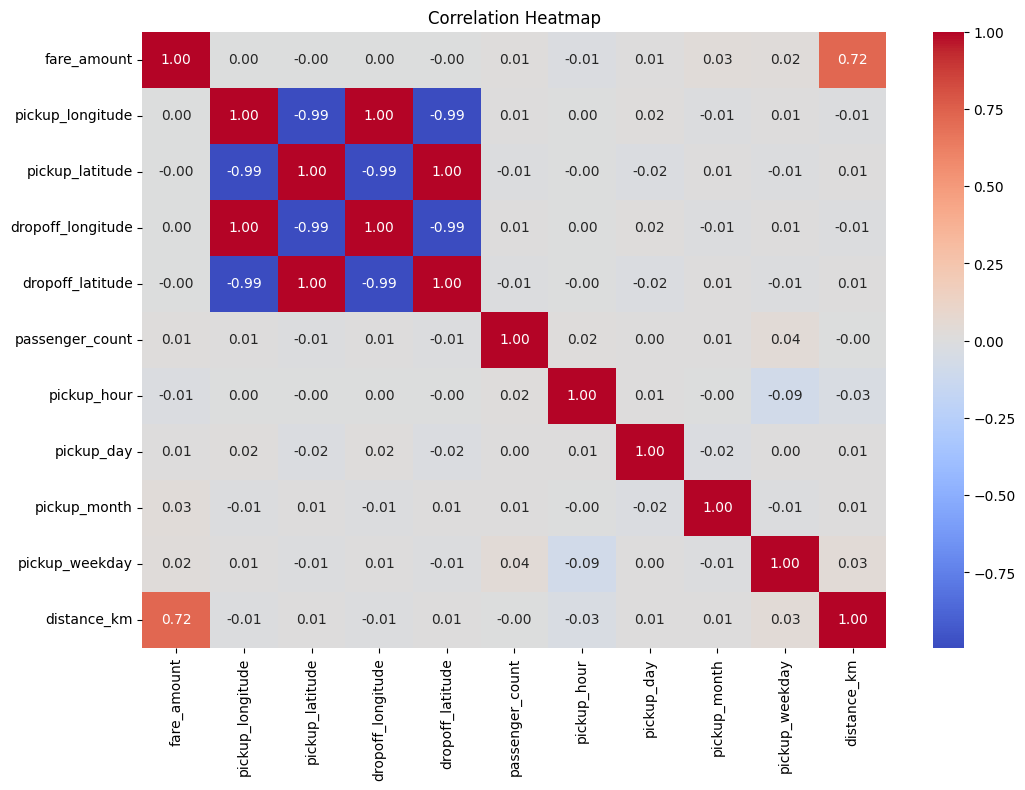

Correlation with Fare Amount:
fare_amount          1.000000
distance_km          0.724921
pickup_month         0.027292
pickup_weekday       0.020412
passenger_count      0.012615
pickup_day           0.006480
dropoff_longitude    0.002400
pickup_longitude     0.001552
pickup_latitude     -0.002362
dropoff_latitude    -0.002565
pickup_hour         -0.013544
Name: fare_amount, dtype: float64


In [21]:
# Select numerical columns
corr_columns = [
    'fare_amount',
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'passenger_count',
    'pickup_hour',
    'pickup_day',
    'pickup_month',
    'pickup_weekday',
    'distance_km'
]

correlation = df[corr_columns].corr()

# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

# Correlation with fare amount
print("Correlation with Fare Amount:")
print(correlation['fare_amount'].sort_values(ascending=False))


In [22]:
features = [
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'passenger_count',
    'pickup_hour',
    'pickup_day',
    'pickup_month',
    'pickup_weekday',
    'distance_km'
]

X = df[features]
y = df['fare_amount']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (140574, 10)
Testing data: (35144, 10)


In [23]:
# Create Linear Regression model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

# Predict fares
lr_predictions = lr_model.predict(X_test)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [25]:
# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict fares
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [26]:
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return {
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }


# Evaluate Linear Regression
lr_results = evaluate_model(
    "Linear Regression",
    y_test,
    lr_predictions
)

# Evaluate Random Forest
rf_results = evaluate_model(
    "Random Forest Regression",
    y_test,
    rf_predictions
)

# Compare models
results = pd.DataFrame([lr_results, rf_results])

print("Model Performance Comparison:")
display(results)

Model Performance Comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.870022,7.728672,2.780049,0.546068
1,Random Forest Regression,1.464370,4.299368,2.073492,0.747483


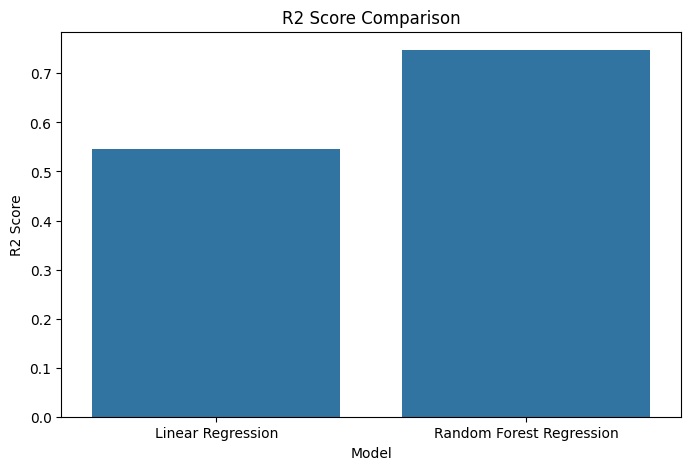

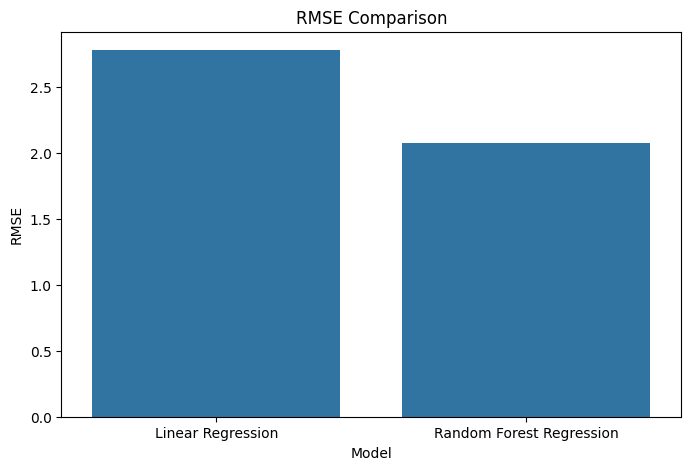

In [27]:
# Compare R2 scores
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='R2 Score'
)

plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.show()


# Compare RMSE
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='RMSE'
)

plt.title("RMSE Comparison")
plt.ylabel("RMSE")
plt.show()

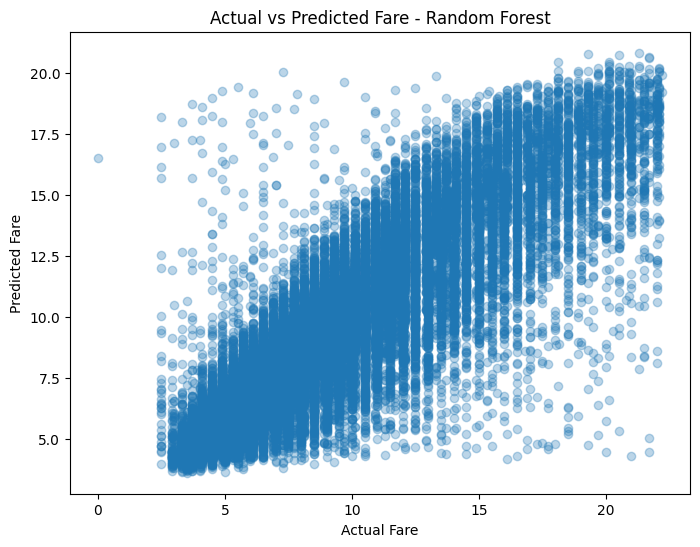

In [28]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.3
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Fare - Random Forest")

plt.show()